# 迴歸 Regression


In [2]:
# 一次載入本課需要的套件，後面的模型儲存格可以專注在操作。
import sys
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import joblib
from IPython.display import display
from sklearn.base import clone
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, PolynomialFeatures
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.ensemble import RandomForestRegressor
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, root_mean_squared_error, r2_score
from sklearn.inspection import permutation_importance

pd.set_option("display.max_columns", 24)
plt.rcParams["figure.figsize"] = (8, 4)
print("Python:", sys.version.split()[0], "sklearn:", sklearn.__version__)
print("Kernel:", sys.executable)


Python: 3.12.13 sklearn: 1.9.1
Kernel: d:\github\python-machine-learning\.venv\Scripts\python.exe


## 迴歸任務與資料準備

迴歸是預測數值：月租金、銷售額、工時等。分類是預測類別：是否購買、是否故障等。

### 主案例：預測房屋月租金

這裡假設每列是獨立房屋。先檢查欄位是否在報價前可取得；成交後資訊不能拿來預測報價。

| 欄位 | 意義 | 模型用途 |
|---|---|---|
| property_id | 房屋識別碼 | 用來對應結果，不作特徵 |
| area_ping | 室內面積（坪） | 數值 Features |
| building_age | 屋齡（年） | 數值 Features |
| distance_mrt_m | 距捷運（公尺） | 數值 Features |
| bedrooms | 臥室數 | 數值 Features |
| floor | 樓層 | 數值 Features |
| district | Central / West / East / North 區域 | 類別 Features |
| has_elevator | Yes / No，是否有電梯 | 類別 Features |
| monthly_rent | 月租金（元） | Target |

資料包含少量 Features 缺失，Target 完整。


In [3]:
from pathlib import Path

lesson_dir = Path("../regression")
df = pd.read_csv(lesson_dir / "data" / "rental_housing.csv")
display(df.head(8))
print("資料形狀:", df.shape)
df.info()

,property_id,area_ping,building_age,distance_mrt_m,bedrooms,floor,district,has_elevator,monthly_rent
0,H0001,15.4,32.0,2196.0,1.0,15.0,West,Yes,16414
1,H0002,10.1,5.0,553.0,1.0,14.0,Central,Yes,19425
2,H0003,51.8,24.0,412.0,4.0,2.0,East,Yes,50537
3,H0004,35.0,7.0,1842.0,4.0,7.0,East,Yes,35862
4,H0005,46.8,45.0,520.0,4.0,8.0,West,Yes,40165
5,H0006,35.2,42.0,1360.0,4.0,13.0,North,Yes,28976
6,H0007,33.5,31.0,NaN,3.0,5.0,North,Yes,27052
7,H0008,42.2,32.0,1160.0,4.0,15.0,West,Yes,36083


資料形狀: (600, 9)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 600 entries, 0 to 599
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   property_id     600 non-null    object 
 1   area_ping       582 non-null    float64
 2   building_age    565 non-null    float64
 3   distance_mrt_m  579 non-null    float64
 4   bedrooms        593 non-null    float64
 5   floor           591 non-null    float64
 6   district        584 non-null    object 
 7   has_elevator    593 non-null    object 
 8   monthly_rent    600 non-null    int64  
dtypes: float64(5), int64(1), object(3)
memory usage: 42.3+ KB


In [4]:
# 接手資料時，先看空值、範圍與重複 ID
display(df.isna().sum().to_frame("缺失筆數"))
display(df.describe().round(1))

,缺失筆數
property_id,0
area_ping,18
building_age,35
distance_mrt_m,21
bedrooms,7
floor,9
district,16
has_elevator,7
monthly_rent,0


,area_ping,building_age,distance_mrt_m,bedrooms,floor,monthly_rent
count,582.0,565.0,579.0,593.0,591.0,600.0
mean,32.4,22.7,1139.4,2.5,8.1,30950.4
std,12.8,13.4,595.1,1.1,4.3,11255.6
min,10.1,0.0,115.0,1.0,1.0,9288.0
25%,21.9,11.0,645.5,2.0,5.0,21259.2
50%,32.2,23.0,1142.0,2.0,8.0,30527.5
75%,42.8,35.0,1634.5,3.0,12.0,39544.2
max,55.0,45.0,2196.0,4.0,15.0,58342.0


### 切割資料

- 訓練集：模型與補值器學規則。
- 驗證集：比較模型與設定。
- 測試集：選定策略後，只做最後評估。
- 本課以 60% / 20% / 20% 分配。後期再進一步介紹交叉驗證與系統調參。
- 回歸 y 是連續數值，**不要直接使用 `stratify=y`**。
- 若資料是時間序列、同一房屋重複刊登或同一建案多筆，應改用時間或群組切分。


In [5]:
# 明確指定 Features，排除 ID 與 Target，所有補值稍後才在 Pipeline fit。
numeric_features = ["area_ping", "building_age", "distance_mrt_m", "bedrooms", "floor"]
categorical_features = ["district", "has_elevator"]
feature_columns = numeric_features + categorical_features
X = df[feature_columns].copy()
y = df["monthly_rent"].copy()

# 先保留 20% 最終測試集，再從其餘 80% 切出 25%，等於總資料的 20%。
X_development, X_test, y_development, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
X_train, X_valid, y_train, y_valid = train_test_split(
    X_development, y_development, test_size=0.25, random_state=42
)
print("訓練 / 驗證 / 測試筆數:", len(X_train), len(X_valid), len(X_test))

訓練 / 驗證 / 測試筆數: 360 120 120


![](./images/regression_workflow.png)

## Model Evaluation：先知道怎麼看效果

模型完成訓練後，可以使用 `predict()` 產生預測結果。

但只有預測結果還不夠，我們還需要知道**模型預測得準不準？**

假設某間房子的真實月租金是 **20,000 元**，模型預測 **22,000 元**：

$$
\text{誤差} = 22,000 - 20,000 = 2,000
$$

也就是模型這次預測差了 2,000 元。

如果資料有很多筆，我們就需要一些指標，把所有資料的「預測值」與「真實值」進行比較。

這一章會使用四個常見的迴歸評估指標：

| 指標 | 用文字理解 | 單位 | 越好方向 |
|---|---|---|---|
| MAE | 每筆差距取絕對值後平均，最容易對業務說明 | 元 | 越小越好 |
| MSE | 將誤差平方後再平均，大誤差會被明顯放大 | 元平方 | 越小越好 |
| RMSE | 對 MSE 開根號，回到原本單位 | 元 | 越小越好 |
| R² | 模型相較於「全部猜平均值」改善了多少 | 無單位 | 越接近 1 越好，可為負 |



### MAE：平均到底差多少？

MAE（Mean Absolute Error，平均絕對誤差）可以直接理解成：**模型平均一筆會猜錯多少錢？**



例如 MAE = 2,000 元，可以粗略理解為模型的預測結果平均與真實值相差約 2,000 元。

$$
MAE = \frac{1}{n}\sum_{i=1}^{n}|y_i-\hat{y}_i|
$$

因為使用絕對值，所以不會發生「高估 2,000 元」與「低估 2,000 元」互相抵銷的問題。

![](./images/MAE.png)

### MSE：特別懲罰猜得很離譜的結果

MSE 會先把每筆誤差平方，再計算平均：

$$
MSE = \frac{1}{n}\sum_{i=1}^{n}(y_i-\hat{y}_i)^2
$$

例如兩筆資料分別猜錯：

$$
2,000,\quad 10,000
$$

平方後會變成：

$$
2,000^2,\quad 10,000^2
$$

因此，**錯得越離譜的資料會受到更大的懲罰**。

缺點是平方後單位也跟著平方。租金原本是「元」，MSE 就會變成「元平方」，不太適合直接拿來向一般使用者解釋。

![](./images/MSE.png)


### RMSE：讓 MSE 回到原本的單位

RMSE 就是把 MSE 再開根號：

![](./images/RMSE.png)

### R²：模型有沒有比「全部猜平均值」更有用？

R² 的思考方式和前面三個不太一樣。

假設完全不建立模型，而是直接把訓練資料的平均租金當成預測基準：「不管看到什麼房子，我都猜平均租金。」

R² 就是在比較：

$$
\text{你的模型}
\quad vs. \quad
\text{用平均值預測的基準}
$$

常見情況可以這樣理解：

| R² | 簡單理解 |
|---|---|
| 接近 1 | 模型能解釋資料中相當多的變化 |
| 接近 0 | 表現接近「猜平均值」的基準 |
| 小於 0 | 甚至比基準還差 |

例如 $R^2 = 0.80$，代表模型解釋了這批資料中約 **80% 的目標變異**。

要注意，R² = 0.80 **不是「預測準確率 80%」**，迴歸問題不能這樣解讀。

![](./images/R平方.png)


## Simple Linear Regression：先用一個 Features

Simple Linear Regression 的概念是：
$$
\boxed{\text{1 個 Feature} \rightarrow \text{1 個 Target}}
$$

檔案中 monthly_rent 是 Target，而 area_ping 是房屋坪數。   

所以很適合先做：
$$
\boxed{\text{area\_ping} \rightarrow \text{monthly\_rent}}
$$



In [6]:
### Simple Linear Regression：只使用一個 Feature 預測 Target
X = df[["area_ping"]].copy() # Feature：房屋坪數，保留 DataFrame 二維格式
y = df["monthly_rent"].copy() # Target：每月租金

In [7]:
### 切割 Train、Validation、Test
from sklearn.model_selection import train_test_split


### 先保留 20% 最終測試集，再從其餘 80% 切出 25%，等於總資料的 20%
X_development, X_test, y_development, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

X_train, X_valid, y_train, y_valid = train_test_split(
    X_development, y_development, test_size=0.25, random_state=42
)

print("訓練 / 驗證 / 測試筆數：", len(X_train), len(X_valid), len(X_test))

訓練 / 驗證 / 測試筆數： 360 120 120


In [8]:
### 建立 Simple Linear Regression(沿用Pipeline版本)
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn import set_config

set_config(display="text") # 避免 Windows cp950 造成模型 HTML 顯示錯誤

### 建立 Simple Linear Regression Pipeline
model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")), # 使用訓練資料的中位數填補缺失坪數
    ("regression", LinearRegression()) # 建立簡單線性迴歸模型
])

### 使用訓練集訓練模型
model.fit(X_train, y_train)

Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('regression', LinearRegression())])

In [9]:
### 使用驗證集進行預測
y_valid_pred = model.predict(X_valid)

print("前 5 筆實際租金：")
print(y_valid.head().to_numpy())

print("\n前 5 筆預測租金：")
print(y_valid_pred[:5])

前 5 筆實際租金：
[17113 34600 42475 32338 48625]

前 5 筆預測租金：
[16874.24749256 33670.47605983 42238.24921788 23321.2847204
 46479.7210783 ]


In [10]:
### 計算 MAE、MSE、RMSE、R²
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np


### 評估 Validation Set
mae = mean_absolute_error(y_valid, y_valid_pred)
mse = mean_squared_error(y_valid, y_valid_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_valid, y_valid_pred)

print(f"MAE(平均差多少元)：{mae:.2f}")
print(f"MSE(把大誤差懲罰得更重)：{mse:.2f}")
print(f"RMSE(誤差重新回到「元」)：{rmse:.2f}")
print(f"R²(模型解釋租金變化的程度)：{r2:.4f}")

MAE(平均差多少元)：3503.72
MSE(把大誤差懲罰得更重)：22924772.72
RMSE(誤差重新回到「元」)：4787.98
R²(模型解釋租金變化的程度)：0.7965


In [11]:
### 取得訓練完成的 Linear Regression
linear_model = model.named_steps["regression"]

intercept = linear_model.intercept_ # 截距 b0
coefficient = linear_model.coef_[0] # 斜率 b1

print(f"截距：{intercept:.2f}")
print(f"坪數係數：{coefficient:.2f}")

截距：3301.54
坪數係數：848.29


也就是說：

$$
\boxed{
\widehat{\text{monthly\_rent}}
=
8000+750\times\text{area\_ping}
}
$$

在這個簡單模型裡，坪數每增加 1 坪，模型預測月租金增加約 750 元。

這也是 Simple Linear Regression 很適合當迴歸第一個模型的原因。學生真的看得到那條公式。

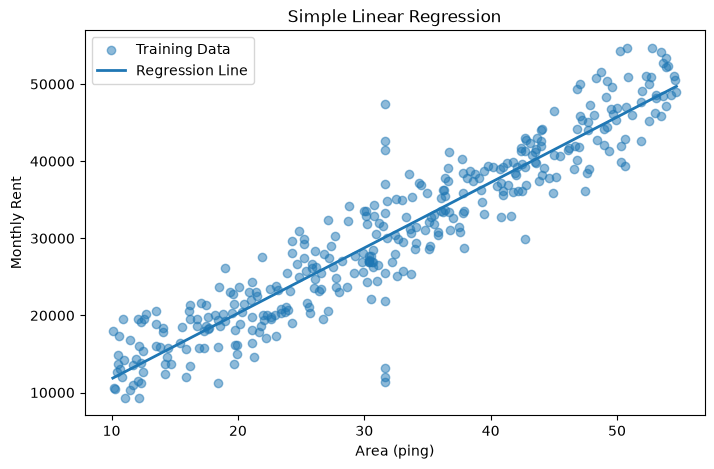

In [12]:
### 畫出迴歸線
import matplotlib.pyplot as plt

### 先取得填補缺失值後的訓練資料
X_train_filled = model.named_steps["imputer"].transform(X_train)

### 依照坪數排序，讓迴歸線由左到右繪製
order = np.argsort(X_train_filled[:, 0])
X_sorted = X_train_filled[order]
y_line = linear_model.predict(X_sorted)

### 繪製實際資料與迴歸線
plt.figure(figsize=(8, 5))
plt.scatter(X_train_filled[:, 0], y_train, alpha=0.5, label="Training Data")
plt.plot(X_sorted[:, 0], y_line, linewidth=2, label="Regression Line")

plt.xlabel("Area (ping)")
plt.ylabel("Monthly Rent")
plt.title("Simple Linear Regression")
plt.legend()
plt.show()

## Multiple Linear Regression：加入更多欄位

面 Simple Linear Regression 是：
$$
\boxed{\text{1 個 Feature} \rightarrow \text{1 個 Target}}
$$
現在 Multiple Linear Regression 改成：
$$
\boxed{\text{多個 Features} \rightarrow \text{1 個 Target}}
$$

套進房租問題：
$$
\boxed{
\hat{y}
=
b_0
+b_1x_1
+b_2x_2
+\cdots
+b_px_p
}
$$

$$
\widehat{\text{Rent}}
=
b_0
+b_1(\text{Area})
+b_2(\text{Age})
+b_3(\text{MRT Distance})
+b_4(\text{Bedrooms})
+b_5(\text{Floor})
+\cdots
$$

模型會替每個 Feature 學習一個係數。

In [13]:
### 指定數值與類別 Features
numeric_features = [
    "area_ping",
    "building_age",
    "distance_mrt_m",
    "bedrooms",
    "floor"
]

categorical_features = [
    "district",
    "has_elevator"
]

feature_columns = numeric_features + categorical_features

X = df[feature_columns].copy() # Features：影響房租的房屋條件
y = df["monthly_rent"].copy() # Target：每月租金

In [14]:
### 切割 Train、Validation、Test
from sklearn.model_selection import train_test_split


### 先保留 20% 最終測試集，訓練集 80% 切出 
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("訓練 / 驗證 / 測試筆數：", len(X_train), len(X_test))

訓練 / 驗證 / 測試筆數： 480 120


In [15]:
### 建立Multiple Linear Regression

from sklearn.linear_model import LinearRegression
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder


### 數值資料前處理
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

### 類別資料前處理
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

### 不同類型的欄位使用不同前處理方式
preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])


### 建立完整 Multiple Linear Regression Pipeline
model = Pipeline([
    ("preprocessor", preprocessor),
    ("regression", LinearRegression())
])

### 使用訓練資料訓練 Multiple Linear Regression
model.fit(X_train, y_train)
print("模型訓練完成")

模型訓練完成


In [16]:
### 使用 Validation Set 預測
y_test_pred = model.predict(X_test)

print("前 5 筆實際租金：")
print(y_test.head().to_numpy())

print("\n前 5 筆預測租金：")
print(y_test_pred[:5])

前 5 筆實際租金：
[38950 24418 40597 32973 49249]

前 5 筆預測租金：
[39526.84576582 25780.28778183 41987.35828314 35616.72500684
 50560.7538392 ]


In [17]:
### 評估 Multiple Linear Regression
mae = mean_absolute_error(y_test, y_test_pred)
mse = mean_squared_error(y_test, y_test_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_test_pred)

print(f"MAE：{mae:.2f} 元")
print(f"MSE：{mse:.2f}")
print(f"RMSE：{rmse:.2f} 元")
print(f"R²：{r2:.4f}")

MAE：1647.30 元
MSE：4259261.56
RMSE：2063.80 元
R²：0.9686


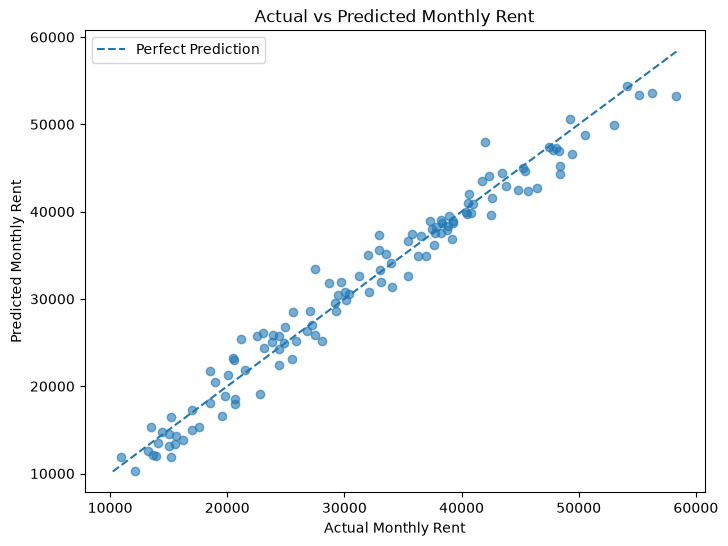

In [18]:
import matplotlib.pyplot as plt


### 視覺化實際租金與預測租金
plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    y_test_pred,
    alpha=0.6
) # 每個點代表一筆房屋資料，X 軸是真實租金，Y 軸是模型預測租金


### 畫出理想預測線 y = x
min_value = min(y_test.min(), y_test_pred.min())
max_value = max(y_test.max(), y_test_pred.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--",
    label="Perfect Prediction"
) # 如果預測完全正確，資料點會落在這條線上


### 圖表設定
plt.xlabel("Actual Monthly Rent")
plt.ylabel("Predicted Monthly Rent")
plt.title("Actual vs Predicted Monthly Rent")
plt.legend()
plt.show()

## Polynomial Regression：讓預測能彎曲

接下來要來討論一件事，如果 $X$ 和 $y$ 的關係根本不是直線，Linear Regression 怎麼辦？

所以最重要的區別是：
$$
\boxed{
Multiple
=
\text{增加不同種類的 Features}
}
$$
而：
$$
\boxed{
Polynomial
=
\text{從原本 Feature 衍生出高次項}
}
$$


| | Multiple Linear Regression | Polynomial Regression |
|---|---|---|
| 原始 Features | 多個不同變數 | 可以只有一個變數 |
| 例如 | 坪數、屋齡、捷運距離 | 坪數 |
| 模型實際收到 | 坪數、屋齡、捷運距離 | 坪數、坪數² |
| 目的 | 同時考慮多種因素 | 描述非線性關係 |
| `sklearn` 最後模型 | `LinearRegression()` | `LinearRegression()` |



![](./images/多項式回歸.png)

In [19]:
import pandas as pd

### 讀取廣告資料
df = pd.read_csv("./data/advertising_curve.csv")

### 指定 Feature 與 Target
X = df[["ad_budget_thousand"]].copy()
y = df["inquiries"].copy()

display(df.head()) # 廣告預算 → 詢問數量

,ad_budget_thousand,inquiries
0,12.67,104
1,11.20,96
2,2.54,40
3,21.39,135
4,19.49,132


In [20]:
### 切割 Train、Validation、Test
from sklearn.model_selection import train_test_split


### 先保留 20% 最終測試集，訓練集 80% 切出 
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("訓練 / 驗證 / 測試筆數：", len(X_train), len(X_test))

訓練 / 驗證 / 測試筆數： 80 20


In [21]:
### 建立Polynomial Regression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline


### 建立 Polynomial Regression
degree = 5

model = Pipeline([
    ("polynomial", PolynomialFeatures(
        degree=degree, # 最高產生到 x²
        include_bias=False # 不額外產生常數 1
    )),
    ("regression", LinearRegression())
])

### 訓練 Polynomial Regression
model.fit(X_train, y_train)

Pipeline(steps=[('polynomial',
                 PolynomialFeatures(degree=5, include_bias=False)),
                ('regression', LinearRegression())])

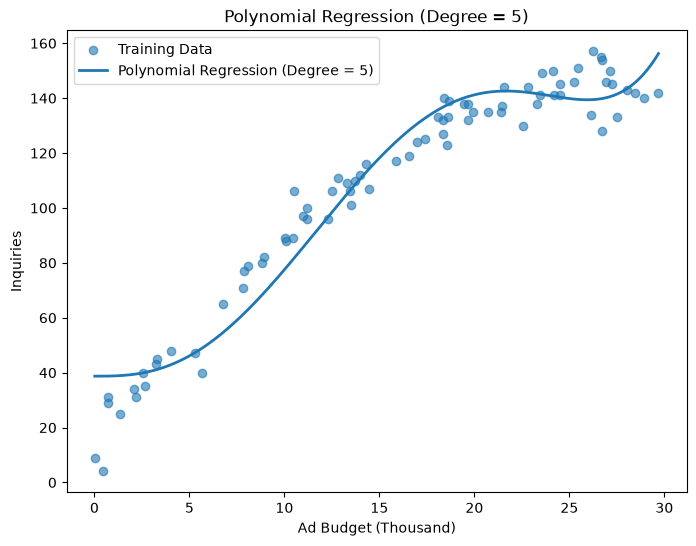

In [22]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

### 建立連續的廣告預算資料，讓曲線更平滑
X_curve = pd.DataFrame({
    "ad_budget_thousand": np.linspace(
        X["ad_budget_thousand"].min(),
        X["ad_budget_thousand"].max(),
        300
    )
})

### 預測不同廣告預算的詢問數
y_curve = model.predict(X_curve)


### 視覺化原始資料與 Polynomial Regression 曲線
plt.figure(figsize=(8, 6))

plt.scatter(
    X_train["ad_budget_thousand"],
    y_train,
    alpha=0.6,
    label="Training Data"
)

plt.plot(
    X_curve["ad_budget_thousand"],
    y_curve,
    linewidth=2,
    label=f"Polynomial Regression (Degree = {degree})"
)

plt.xlabel("Ad Budget (Thousand)")
plt.ylabel("Inquiries")
plt.title(f"Polynomial Regression (Degree = {degree})")
plt.legend()
plt.show()

<p style="text-align: center;">Copyright © 2026 Wei-Cheng Chen</p>